# Brain Tumor MRI Classification

## Setup

In [ ]:
import os
IN_COLAB = 'google.colab' in str(get_ipython())

if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_DIR = '/content/drive/MyDrive/brain_tumor_project'
else:
    PROJECT_DIR = './model'   # local run

os.makedirs(PROJECT_DIR, exist_ok=True)

In [1]:
import os, random
import numpy as np
import tensorflow as tf
import kagglehub

In [2]:
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

In [3]:
# Project folder on Drive
PROJECT_DIR = '/content/drive/MyDrive/brain_tumor_project'
os.makedirs(PROJECT_DIR, exist_ok=True)

## Import Data

In [4]:
DATA_DIR = kagglehub.dataset_download('masoudnickparvar/brain-tumor-mri-dataset')
print('Dataset path:', DATA_DIR)

Using Colab cache for faster access to the 'brain-tumor-mri-dataset' dataset.
Dataset path: /kaggle/input/brain-tumor-mri-dataset


In [ ]:
# Quick structure check
for split in ['Training', 'Testing']:
    split_dir = os.path.join(DATA_DIR, split)
    for cls in sorted(os.listdir(split_dir)):
        n = len(os.listdir(os.path.join(split_dir, cls)))
        print(f'{split:9s} | {cls:11s} | {n}')

print('GPU:', tf.config.list_physical_devices('GPU'))

Training  | glioma      | 1400
Training  | meningioma  | 1400
Training  | notumor     | 1400
Training  | pituitary   | 1400
Testing   | glioma      | 400
Testing   | meningioma  | 400
Testing   | notumor     | 400
Testing   | pituitary   | 400
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Data exploration


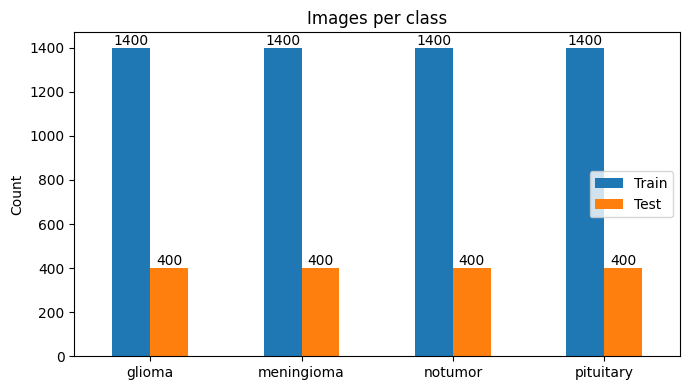

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from collections import Counter

TRAIN_DIR = os.path.join(DATA_DIR, 'Training')
TEST_DIR = os.path.join(DATA_DIR, 'Testing')
CLASSES = sorted(os.listdir(TRAIN_DIR))

counts = {
    'Train': [len(os.listdir(os.path.join(TRAIN_DIR, c))) for c in CLASSES],
    'Test':  [len(os.listdir(os.path.join(TEST_DIR, c))) for c in CLASSES],
}
df = pd.DataFrame(counts, index=CLASSES)

ax = df.plot(kind='bar', figsize=(7, 4), rot=0)
for container in ax.containers:
    ax.bar_label(container)
ax.set_title('Images per class')
ax.set_ylabel('Count')
plt.tight_layout(); plt.show()

Class balance is perfect (1400/class train, 400/class test). Check sample images and image sizes.

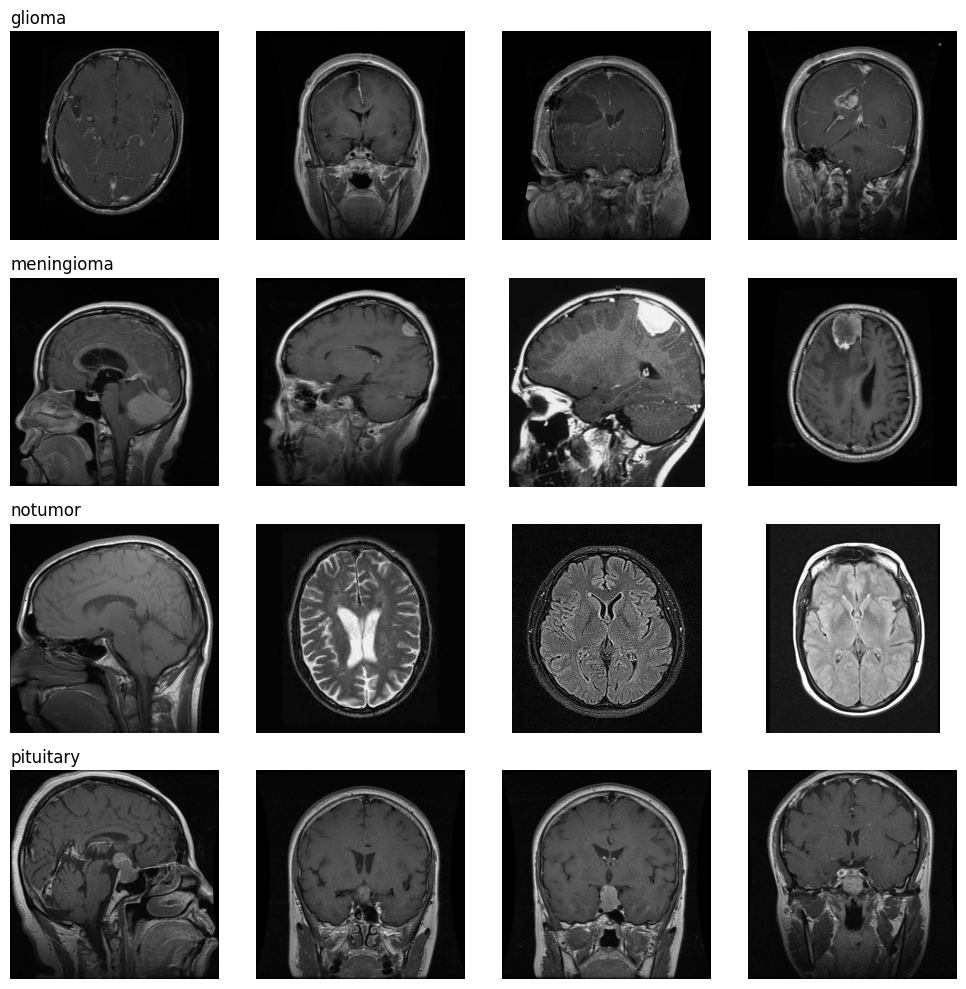

Top sizes: [((512, 512), 863), ((225, 225), 52), ((630, 630), 12), ((442, 442), 11), ((201, 251), 11)]
Modes: Counter({'RGB': 688, 'L': 512})


In [8]:

# 4 random samples per class
fig, axes = plt.subplots(4, 4, figsize=(10, 10))
for i, cls in enumerate(CLASSES):
    files = random.sample(os.listdir(os.path.join(TRAIN_DIR, cls)), 4)
    for j, f in enumerate(files):
        img = Image.open(os.path.join(TRAIN_DIR, cls, f))
        axes[i, j].imshow(img, cmap='gray')
        axes[i, j].axis('off')
        if j == 0:
            axes[i, j].set_title(cls, loc='left')
plt.tight_layout(); plt.show()

# Image size and mode distribution (sample of 300 per class)
sizes, modes = Counter(), Counter()
for cls in CLASSES:
    for f in random.sample(os.listdir(os.path.join(TRAIN_DIR, cls)), 300):
        img = Image.open(os.path.join(TRAIN_DIR, cls, f))
        sizes[img.size] += 1
        modes[img.mode] += 1
print('Top sizes:', sizes.most_common(5))
print('Modes:', modes)

## Preprocessing
150x150 RGB, rescale to [0,1]. Light augmentation on train only. Test set is only rescaled.

**Normalization (rescale to [0,1])**: pixels are 0-255; small inputs keep gradients stable and speed up convergence. A fixed /255 is simple and identical at train and inference time (important for the Streamlit app).

**Resize to 150x150**: the original MRIs have varying sizes and CNNs need a fixed input. 150x150 keeps tumor structure visible while staying light enough to train fast on Colab (vs. 224+ which costs more for little gain here). Kept RGB (3 channels) so it's compatible with pretrained-style inputs and Grad-CAM later.

**Augmentation (train only)**: creates slightly varied copies of the images each epoch, so the model sees more variety and overfits less. Test data is never augmented so evaluation stays honest.

- `rotation_range=10`, `width/height_shift_range=0.002`: small, since MRIs are acquired in a roughly standard position
- `shear_range=12.5`: mild geometric distortion for robustness to slight scan angle differences
- `brightness_range=(0.85, 1.15)`: simulates intensity differences between scanners
- `horizontal_flip=True`: the brain is roughly symmetric, so a flipped image is still a plausible MRI
- No vertical flip or zoom: an upside-down brain is unrealistic, and zoom could crop out the tumor

In [9]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

image_size = (150, 150)
batch_size = 32
image_shape = (*image_size, 3)
epochs = 40

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=10,
    brightness_range=(0.85, 1.15),
    width_shift_range=0.002,
    height_shift_range=0.002,
    shear_range=12.5,
    horizontal_flip=True,
    fill_mode='nearest',
)

test_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    TRAIN_DIR, target_size=image_size, batch_size=batch_size,
    class_mode='categorical', seed=SEED)

test_generator = test_datagen.flow_from_directory(
    TEST_DIR, target_size=image_size, batch_size=batch_size,
    class_mode='categorical', shuffle=False, seed=SEED)

print('Class indices:', train_generator.class_indices)


Found 5600 images belonging to 4 classes.
Found 1600 images belonging to 4 classes.
Class indices: {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}


Image shape: (150, 150, 3) | Steps/epoch: 175 | Val steps: 50


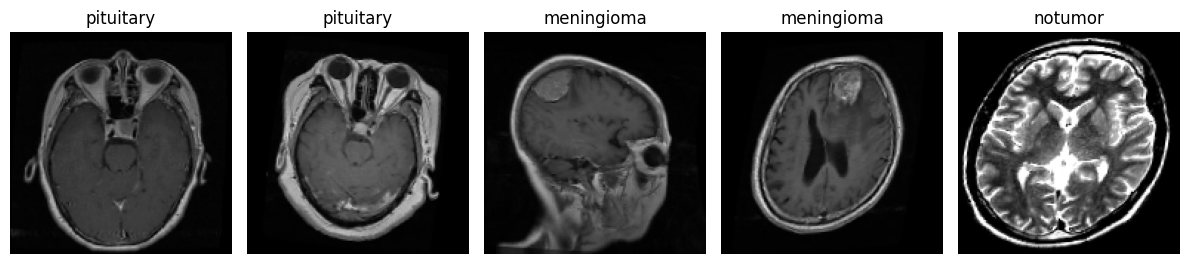

In [10]:
steps_per_epoch = train_generator.samples // batch_size
validation_steps = test_generator.samples // batch_size
print(f'Image shape: {image_shape} | Steps/epoch: {steps_per_epoch} | Val steps: {validation_steps}')

# Preview augmented samples
x, y = next(train_generator)
fig, axes = plt.subplots(1, 5, figsize=(12, 3))
for i in range(5):
    axes[i].imshow(x[i]); axes[i].axis('off')
    axes[i].set_title(CLASSES[y[i].argmax()])
plt.tight_layout(); plt.show()

## Baseline CNN
`build_cnn()` takes `base_filters`, `dropout`, `lr` so the tuning reuses it. Defaults = baseline.

- 4 conv layers (4x4, ReLU), filters f, 2f, 4f, 4f (32, 64, 128, 128): depth increases as the maps shrink.
- 3x3 max pooling after the first 3 convs: 150 → 147 → 49 → 46 → 15 → 12 → 4 → 1.
- `Flatten` keeps spatial information, which matters to separate glioma from meningioma .
- Dense 512 + Dropout + softmax(4).
- `gradcam_conv` (12x12 map) is the layer used for Grad-CAM later.


In [18]:
from tensorflow.keras import layers, models
from tensorflow.keras.optimizers import Adam

N_CLASSES = 4

def build_cnn(base_filters=32, dropout=0.5, lr=1e-3, beta_1=0.869, beta_2=0.995):
    f = base_filters
    model = models.Sequential([
        layers.Input(shape=image_shape),

        layers.Conv2D(f, 4, activation='relu'),
        layers.MaxPooling2D(3),

        layers.Conv2D(2*f, 4, activation='relu'),
        layers.MaxPooling2D(3),

        layers.Conv2D(4*f, 4, activation='relu', name='gradcam_conv'),
        layers.MaxPooling2D(3),

        layers.Conv2D(4*f, 4, activation='relu'),
        layers.Flatten(),

        layers.Dense(512, activation='relu'),
        layers.Dropout(dropout, seed=SEED),
        layers.Dense(N_CLASSES, activation='softmax'),
    ])
    model.compile(optimizer=Adam(learning_rate=lr, beta_1=beta_1, beta_2=beta_2),
                  loss='categorical_crossentropy', metrics=['accuracy'])
    return model

model = build_cnn()
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 147, 147, 32)   │         1,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 49, 49, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 46, 46, 64)     │        32,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 15, 15, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gradcam_conv (Conv2D)           │ (None, 12, 12, 128)    │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 1, 1, 128)      │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 512)            │        66,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 4)              │         2,052 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 495,972 (1.89 MB)

 Trainable params: 495,972 (1.89 MB)

 Non-trainable params: 0 (0.00 B)

## Training
Callbacks: `ModelCheckpoint` (best model saved to Drive), `EarlyStopping` (restores best weights), `ReduceLROnPlateau`. The test set is used as validation.

Epoch 1/40
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 492ms/step - accuracy: 0.4753 - loss: 1.0860
Epoch 1: val_loss improved from None to 1.05538, saving model to /content/drive/MyDrive/brain_tumor_project/baseline_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/brain_tumor_project/baseline_model.keras
175/175 ━━━━━━━━━━━━━━━━━━━━ 117s 594ms/step - accuracy: 0.6102 - loss: 0.8600 - val_accuracy: 0.6806 - val_loss: 1.0554 - learning_rate: 0.0010
Epoch 2/40
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 320ms/step - accuracy: 0.7807 - loss: 0.5594
Epoch 2: val_loss did not improve from 1.05538
175/175 ━━━━━━━━━━━━━━━━━━━━ 62s 355ms/step - accuracy: 0.7907 - loss: 0.5337 - val_accuracy: 0.7100 - val_loss: 1.0824 - learning_rate: 0.0010
Epoch 3/40
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 319ms/step - accuracy: 0.8165 - loss: 0.4677
Epoch 3: val_loss improved from 1.05538 to 0.88906, saving model to /content/drive/MyDrive/brain_tumor_project/baseline_model.keras

Epoch 3: finished saving model to /cont

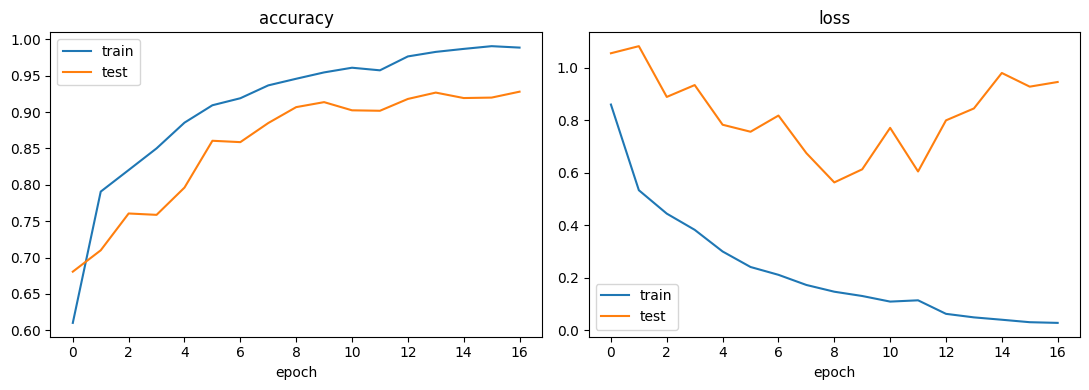

In [12]:
import json
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau

MODEL_PATH = os.path.join(PROJECT_DIR, 'baseline_model.keras')
HISTORY_PATH = os.path.join(PROJECT_DIR, 'baseline_history.json')

callbacks = [
    ModelCheckpoint(MODEL_PATH, monitor='val_loss', save_best_only=True, verbose=1),
    EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=3, min_lr=1e-6, verbose=1),
]

model = build_cnn()
history = model.fit(
    train_generator,
    validation_data=test_generator,
    epochs=epochs,
    callbacks=callbacks,
)

# Save history + class names to Drive (used later by Streamlit)
with open(HISTORY_PATH, 'w') as f:
    json.dump({k: [float(v) for v in vals] for k, vals in history.history.items()}, f)
with open(os.path.join(PROJECT_DIR, 'class_names.json'), 'w') as f:
    json.dump(CLASSES, f)

# Learning curves
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, m in zip(ax, ['accuracy', 'loss']):
    a.plot(history.history[m], label='train')
    a.plot(history.history['val_' + m], label='test')
    a.set_title(m); a.set_xlabel('epoch'); a.legend()
plt.tight_layout()
plt.savefig(os.path.join(PROJECT_DIR, 'baseline_curves.png'), dpi=150)
plt.show()

### Baseline results
- **Convergence:** train accuracy reaches ~99% (loss ~0.03). Test accuracy plateaus at ~92-93% after epoch 8.
- **Overfitting:** the train/test gap grows, and test loss rises again after epoch 8 (up to ~0.95) while train loss keeps falling. `EarlyStopping` restores the best-loss epoch, so the final test metrics come from the weights before the divergence.
- **Takeaway:** the model has enough capacity, so the tuning should target regularization (dropout, learning rate, batch size, filters).

## Model Evaluation

In [13]:
import seaborn as sns

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

# Load the best saved model
model = models.load_model(MODEL_PATH)

# Evaluate on test data
test_loss, test_accuracy = model.evaluate(test_generator, verbose=1)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

# Predictions
test_generator.reset()
y_pred_proba = model.predict(test_generator, verbose=1)
y_pred = np.argmax(y_pred_proba, axis=1)

# True labels
y_true = test_generator.classes

# Class names
class_names = list(test_generator.class_indices.keys())

50/50 ━━━━━━━━━━━━━━━━━━━━ 7s 126ms/step - accuracy: 0.9069 - loss: 0.5635
Test Loss: 0.5635
Test Accuracy: 0.9069
50/50 ━━━━━━━━━━━━━━━━━━━━ 6s 118ms/step


## Classificaiton Report

In [14]:
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
))

              precision    recall  f1-score   support

      glioma     0.9643    0.7425    0.8390       400
  meningioma     0.8515    0.9175    0.8833       400
     notumor     0.8744    0.9925    0.9297       400
   pituitary     0.9582    0.9750    0.9665       400

    accuracy                         0.9069      1600
   macro avg     0.9121    0.9069    0.9046      1600
weighted avg     0.9121    0.9069    0.9046      1600



## Confusion Matrix

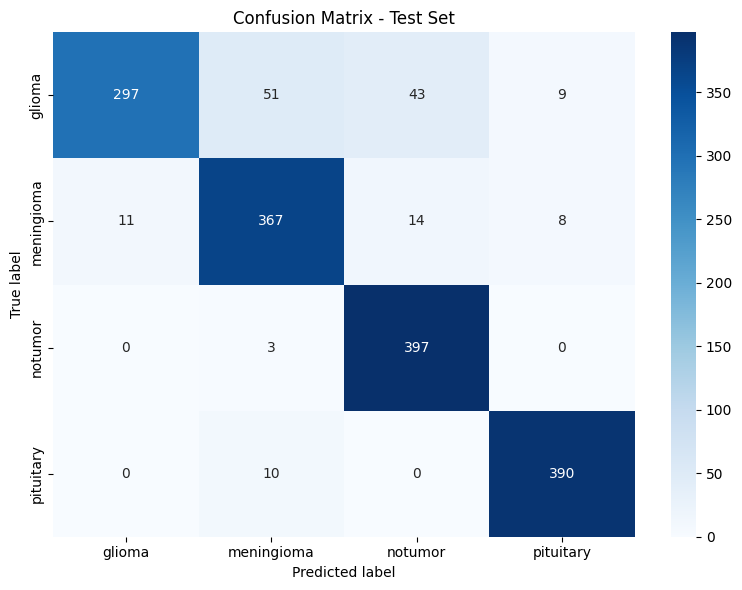

In [15]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.title('Confusion Matrix - Test Set')
plt.tight_layout()
plt.show()

### Baseline evaluation (test set)
- **Test accuracy 90.7%, loss 0.56.** Training accuracy is 99%, so the generalization gap is clear. The best-loss epoch is restored, so this is lower than the last epoch's val accuracy (~93%).
- **Pituitary and notumor are easy:** pituitary F1 0.97, notumor recall 0.99.
- **Glioma is the weak class:** precision 0.96 but recall 0.74. Of 400 gliomas, 51 are predicted meningioma and 43 notumor. The model is conservative on glioma.
- **Notumor precision is lower (0.87)** because 43 gliomas and 14 meningiomas are labelled "no tumor". These false negatives are the most serious errors in a medical setting.
- **Target for tuning:** better regularization and glioma recall.

## Hyperparamters Tuning

##  Helpers for tuning
`make_gens(bs)` rebuilds the generators for a given batch size. `train()` trains with the same callbacks as the baseline and saves the model, history and parameters to Drive.

In [19]:
import gc

def make_gens(bs):
    tr = train_datagen.flow_from_directory(TRAIN_DIR, target_size=image_size, batch_size=bs,
                                           class_mode='categorical', seed=SEED)
    te = test_datagen.flow_from_directory(TEST_DIR, target_size=image_size, batch_size=bs,
                                          class_mode='categorical', shuffle=False)
    return tr, te


def train(tag, base_filters=32, dropout=0.5, lr=1e-3, bs=32, beta_1=0.869, beta_2=0.995, epochs=40):
    tr, te = make_gens(bs)
    model = build_cnn(base_filters, dropout, lr, beta_1, beta_2)
    cbs = [
        ModelCheckpoint(f'{PROJECT_DIR}/{tag}_model.keras', monitor='val_loss', save_best_only=True),
        EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True),
        ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=3, min_lr=1e-6),
    ]
    h = model.fit(tr, validation_data=te, epochs=epochs, callbacks=cbs)
    json.dump({k: [float(v) for v in vs] for k, vs in h.history.items()},
              open(f'{PROJECT_DIR}/{tag}_history.json', 'w'))
    json.dump(dict(base_filters=base_filters, dropout=dropout, lr=lr, batch_size=bs,
                   beta_1=beta_1, beta_2=beta_2),
              open(f'{PROJECT_DIR}/{tag}_params.json', 'w'))
    return model, h.history

## Hyperparameter search (Optuna)
Searches learning rate, batch size, number of filters and dropout. Short runs (10 epochs, early stopping), maximizing test accuracy.

In [17]:
!pip -q install optuna

In [20]:
import optuna

N_TRIALS = 15

def objective(trial):
    p = dict(
        lr=trial.suggest_float('lr', 1e-4, 3e-3, log=True),
        bs=trial.suggest_categorical('bs', [16, 32, 64]),
        base_filters=trial.suggest_categorical('base_filters', [16, 32, 64]),
        dropout=trial.suggest_float('dropout', 0.3, 0.6, step=0.1),
        beta_1=trial.suggest_float('beta_1', 0.7, 0.995),
        beta_2=trial.suggest_float('beta_2', 0.9, 0.9995),
    )
    tr, te = make_gens(p['bs'])
    model = build_cnn(p['base_filters'], p['dropout'], p['lr'], p['beta_1'], p['beta_2'])
    h = model.fit(tr, validation_data=te, epochs=10, verbose=0,
                  callbacks=[EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)])
    tf.keras.backend.clear_session(); gc.collect()
    return max(h.history['val_accuracy'])

study = optuna.create_study(
    direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED),
    study_name='brain_tumor_betas', storage=f'sqlite:///{PROJECT_DIR}/optuna.db', load_if_exists=True)

study.optimize(objective, n_trials=max(0, N_TRIALS - len(study.trials)))

print('Best val acc:', study.best_value)
print('Best params:', study.best_params)
study.trials_dataframe()[['number', 'value', 'params_lr', 'params_bs', 'params_base_filters',
                          'params_dropout', 'params_beta_1', 'params_beta_2']].sort_values('value', ascending=False)

[I 2026-11-12 17:09:53,181] A new study created in RDB with name: brain_tumor_betas


Found 5600 images belonging to 4 classes.
Found 1600 images belonging to 4 classes.


[I 2026-11-12 17:20:03,995] Trial 0 finished with value: 0.8668749928474426 and parameters: {'lr': 0.0003574712922600243, 'bs': 16, 'base_filters': 16, 'dropout': 0.6, 'beta_1': 0.8773289284642466, 'beta_2': 0.9704532214907066}. Best is trial 0 with value: 0.8668749928474426.


Found 5600 images belonging to 4 classes.
Found 1600 images belonging to 4 classes.


[I 2026-11-12 17:31:17,599] Trial 1 finished with value: 0.8868749737739563 and parameters: {'lr': 0.00010725209743172001, 'bs': 16, 'base_filters': 64, 'dropout': 0.5, 'beta_1': 0.8274237804994241, 'beta_2': 0.9289772994497052}. Best is trial 1 with value: 0.8868749737739563.


Found 5600 images belonging to 4 classes.
Found 1600 images belonging to 4 classes.


... (23 outputs left out)

Found 5600 images belonging to 4 classes.
Found 1600 images belonging to 4 classes.


[I 2026-11-12 19:30:11,877] Trial 14 finished with value: 0.9137499928474426 and parameters: {'lr': 0.000489953556710553, 'bs': 64, 'base_filters': 64, 'dropout': 0.5, 'beta_1': 0.7635347074276274, 'beta_2': 0.9311884510668756}. Best is trial 14 with value: 0.9137499928474426.


Best val acc: 0.9137499928474426
Best params: {'lr': 0.000489953556710553, 'bs': 64, 'base_filters': 64, 'dropout': 0.5, 'beta_1': 0.7635347074276274, 'beta_2': 0.9311884510668756}


,number,value,params_lr,params_bs,params_base_filters,params_dropout,params_beta_1,params_beta_2
14,14,0.913750,0.000490,64,64,0.5,0.763535,0.931188
13,13,0.912500,0.000539,64,64,0.4,0.722623,0.923540
12,12,0.902500,0.000761,64,64,0.4,0.757700,0.902902
11,11,0.901875,0.001437,64,64,0.3,0.733941,0.904273
7,7,0.895000,0.001383,64,64,0.3,0.805747,0.911529
1,1,0.886875,0.000107,16,64,0.5,0.827424,0.928977
2,2,0.883750,0.000801,64,32,0.5,0.874762,0.904622
5,5,0.871875,0.002705,32,32,0.3,0.713342,0.932370
6,6,0.871250,0.000375,32,32,0.6,0.721992,0.998195
3,3,0.868125,0.000790,64,16,0.3,0.901849,0.943795


## Train the optimized model
Full training (callbacks) with the best parameters. Saved to Drive as `best_model.keras`.

In [21]:
best = study.best_params
best_model, best_hist = train('best', base_filters=best['base_filters'],
                              dropout=best['dropout'], lr=best['lr'], bs=best['bs'])

Found 5600 images belonging to 4 classes.
Found 1600 images belonging to 4 classes.
Epoch 1/40
88/88 ━━━━━━━━━━━━━━━━━━━━ 74s 773ms/step - accuracy: 0.5921 - loss: 0.9254 - val_accuracy: 0.6712 - val_loss: 0.9005 - learning_rate: 4.8995e-04
Epoch 2/40
88/88 ━━━━━━━━━━━━━━━━━━━━ 62s 702ms/step - accuracy: 0.7391 - loss: 0.6189 - val_accuracy: 0.6656 - val_loss: 1.0744 - learning_rate: 4.8995e-04
Epoch 3/40
88/88 ━━━━━━━━━━━━━━━━━━━━ 59s 672ms/step - accuracy: 0.8030 - loss: 0.4864 - val_accuracy: 0.7719 - val_loss: 0.7768 - learning_rate: 4.8995e-04
Epoch 4/40
88/88 ━━━━━━━━━━━━━━━━━━━━ 58s 661ms/step - accuracy: 0.8470 - loss: 0.4035 - val_accuracy: 0.7644 - val_loss: 0.8266 - learning_rate: 4.8995e-04
Epoch 5/40
88/88 ━━━━━━━━━━━━━━━━━━━━ 60s 678ms/step - accuracy: 0.8666 - loss: 0.3412 - val_accuracy: 0.8131 - val_loss: 0.7513 - learning_rate: 4.8995e-04
Epoch 6/40
88/88 ━━━━━━━━━━━━━━━━━━━━ 60s 686ms/step - accuracy: 0.9025 - loss: 0.2610 - val_accuracy: 0.7962 - val_loss: 0.8286 - 

## Baseline vs optimized
Metrics, curves and stability (std of test accuracy over the last 5 epochs). Optimized metrics are saved for Streamlit.

,model,test_loss,test_acc,glioma_recall,macro_f1,val_acc_std_last5,epochs_run
0,baseline,0.5635,0.9069,0.7425,0.9046,0.0041,17
1,best,0.4511,0.9294,0.8075,0.9281,0.0025,21


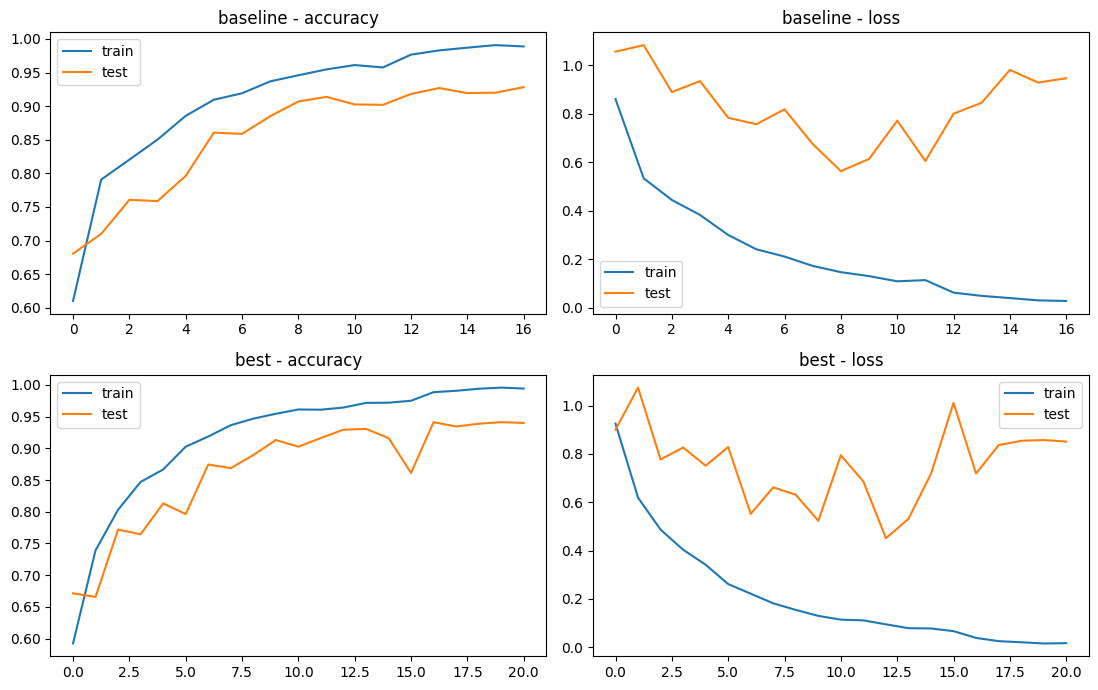

              precision    recall  f1-score   support

      glioma       0.94      0.81      0.87       400
  meningioma       0.90      0.93      0.92       400
     notumor       0.90      0.99      0.94       400
   pituitary       0.98      0.99      0.98       400

    accuracy                           0.93      1600
   macro avg       0.93      0.93      0.93      1600
weighted avg       0.93      0.93      0.93      1600



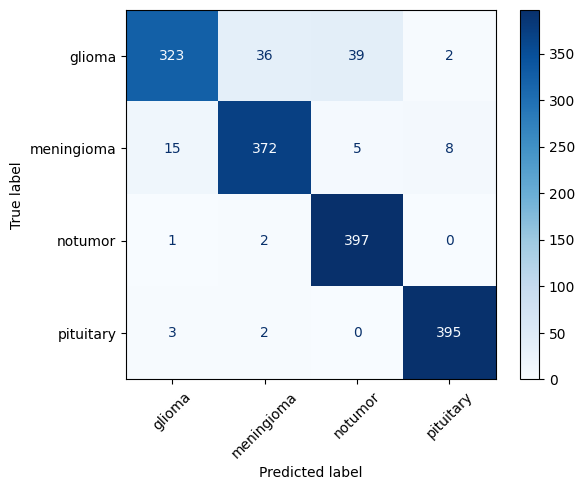

In [22]:
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

def evaluate(model):
    loss, acc = model.evaluate(test_generator, verbose=0)
    test_generator.reset()
    y_pred = model.predict(test_generator, verbose=0).argmax(axis=1)
    y_true = test_generator.classes
    rep = classification_report(y_true, y_pred, target_names=CLASSES, output_dict=True)
    return loss, acc, rep, confusion_matrix(y_true, y_pred), y_pred

results, hists = {}, {}
for tag in ['baseline', 'best']:
    m = tf.keras.models.load_model(f'{PROJECT_DIR}/{tag}_model.keras')
    results[tag] = evaluate(m)
    hists[tag] = json.load(open(f'{PROJECT_DIR}/{tag}_history.json'))

# Metrics table
rows = []
for tag, (loss, acc, rep, cm, _) in results.items():
    h = hists[tag]
    rows.append({'model': tag, 'test_loss': loss, 'test_acc': acc,
                 'glioma_recall': rep['glioma']['recall'],
                 'macro_f1': rep['macro avg']['f1-score'],
                 'val_acc_std_last5': np.std(h['val_accuracy'][-5:]),
                 'epochs_run': len(h['loss'])})
display(pd.DataFrame(rows).round(4))

# Curves
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for r, tag in enumerate(['baseline', 'best']):
    for c, m in enumerate(['accuracy', 'loss']):
        axes[r, c].plot(hists[tag][m], label='train')
        axes[r, c].plot(hists[tag]['val_' + m], label='test')
        axes[r, c].set_title(f'{tag} - {m}'); axes[r, c].legend()
plt.tight_layout()
plt.savefig(f'{PROJECT_DIR}/comparison_curves.png', dpi=150); plt.show()

# Optimized model: report + confusion matrix
loss, acc, rep, cm, y_pred = results['best']
print(classification_report(test_generator.classes, y_pred, target_names=CLASSES))
ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(cmap='Blues', xticks_rotation=45)
plt.savefig(f'{PROJECT_DIR}/best_confusion_matrix.png', dpi=150, bbox_inches='tight'); plt.show()

# Everything the Streamlit app needs
json.dump({'test_loss': loss, 'test_accuracy': acc, 'report': rep, 'confusion_matrix': cm.tolist(),
           'params': json.load(open(f'{PROJECT_DIR}/best_params.json'))},
          open(f'{PROJECT_DIR}/best_metrics.json', 'w'), indent=2)

### Baseline vs optimized (test set)
| | Baseline | Optimized |
|---|---|---|
| Test accuracy | 90.7% | **92.9%** |
| Test loss | 0.56 | **0.45** |
| Glioma recall | 0.74 | **0.81** |
| Macro F1 | 0.905 | **0.928** |
| Std of test acc (last 5 epochs) | 0.0041 | **0.0025** |

- **Better on every metric**, and more stable. The biggest gain is glioma recall (+6 points).
- **Remaining weakness:** glioma is still confused with meningioma (36) and notumor (39). Tumors predicted as "no tumor" drop from 57 to 44 out of 1200, which matters most clinically.
- **Overfitting persists:** train accuracy is 99% in both runs and test loss rises after its minimum (epoch 12). `ModelCheckpoint` + `EarlyStopping` keep the best-loss weights, so the reported metrics come from before the divergence.
- **Limits:** the test set was also used for tuning, so these numbers are slightly optimistic. Differences are real but modest.